In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import ipywidgets as widgets
from ipywidgets import interact

df = pd.read_csv('../datasets/dataset_clean.csv')

X = df[['tahun_pengalaman_kerja']].values
y = df['gaji_pokok_bulanan_idr'].values / 1e6

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
                                                    
print("Setup ready!")

Setup ready!


R2 Score: 0.8098
RMSE: 10.57 Juta IDR


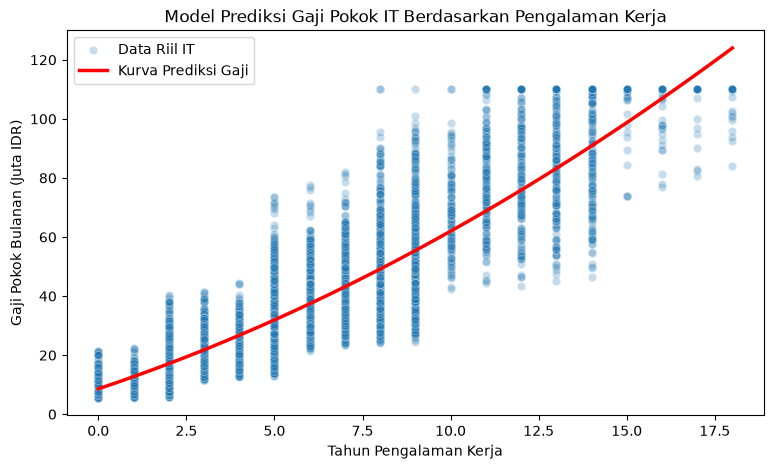

In [3]:
# Menggunakan Regresi Polinomial Orde 2 untuk menangkap kurva kenaikan karir
model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} Juta IDR")

# Visualisasi Garis Regresi
plt.figure(figsize=(9, 5))
sns.scatterplot(x=df['tahun_pengalaman_kerja'], y=y, alpha=0.25, label='Data Riil IT')

x_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_range, model.predict(x_range), color='red', linewidth=2.5, label='Kurva Prediksi Gaji')

plt.title('Model Prediksi Gaji Pokok IT Berdasarkan Pengalaman Kerja')
plt.xlabel('Tahun Pengalaman Kerja')
plt.ylabel('Gaji Pokok Bulanan (Juta IDR)')
plt.legend()
plt.show()

In [4]:
posisi_options = ['Semua Posisi'] + sorted(df['posisi_pekerjaan_clean'].dropna().unique().tolist())
lokasi_options = ['Semua Lokasi'] + sorted(df['lokasi_kantor'].dropna().unique().tolist())
tipe_options = ['Semua Tipe'] + sorted(df['skala_perusahaan'].dropna().unique().tolist())

def prediksi_gaji_multi_filter(posisi, lokasi, skala_perusahaan, pengalaman_tahun):
    df_filtered = df.copy()

    if posisi != 'Semua Posisi':
        df_filtered = df_filtered[df_filtered['posisi_pekerjaan_clean'] == posisi]
    if lokasi != 'Semua Lokasi':
        df_filtered = df_filtered[df_filtered['lokasi_kantor'] == lokasi]
    if skala_perusahaan != 'Semua Tipe':
        df_filtered = df_filtered[df_filtered['skala_perusahaan'] == skala_perusahaan]

    jumlah_data = len(df_filtered)

    print("==========================================================")
    print("                PANEL ESTIMASI GAJI IT                    ")
    print("==========================================================")
    print(f" Posisi Pekerjaan : {posisi}")
    print(f" Lokasi Kantor    : {lokasi}")
    print(f" Tipe Perusahaan  : {skala_perusahaan}")
    print(f" Pengalaman Kerja : {pengalaman_tahun} Tahun")
    print(f" Data Pendukung   : {jumlah_data} sampel sampel karyawan")
    print("----------------------------------------------------------")

    if jumlah_data < 5:
        print(" [PERINGATAN] Data tidak mencukupi untuk regresi terpisah.")
        print(" Silakan longgarkan kombinasi filter (misal: set Lokasi ke 'Semua Lokasi').")
        print("==========================================================")
        return

    X_f = df_filtered[['tahun_pengalaman_kerja']].values
    y_f = df_filtered['gaji_pokok_bulanan_idr'].values / 1e6
    
    model_filtered = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
    model_filtered.fit(X_f, y_f)

    estimasi = model_filtered.predict([[pengalaman_tahun]])[0]
    estimasi = max(0, estimasi)

    print(f" EST. GAJI POKOK  : Rp {estimasi:.2f} Juta / bulan")
    print(f" Rentang Riil Data : Rp {y_f.min():.2f} Juta - Rp {y_f.max():.2f} Juta")
    print("==========================================================")

interact(
    prediksi_gaji_multi_filter, 
    posisi=widgets.Dropdown(options=posisi_options, value='Fullstack Engineer', description='Posisi:'),
    lokasi=widgets.Dropdown(options=lokasi_options, value='Jakarta Selatan / SCBD', description='Lokasi:'),
    skala_perusahaan=widgets.Dropdown(options=tipe_options, value='Software House / IT Agency', description='Tipe Perusahaan:'),
    pengalaman_tahun=widgets.IntSlider(min=0, max=15, step=1, value=1, description='Exp (Thn):')
);

interactive(children=(Dropdown(description='Posisi:', index=7, options=('Semua Posisi', 'Backend Engineer', 'C…